# 7. Sequential filtering & process noise

> Process the same tracking data one epoch at a time with the sequential filters `SRIF` and `LKF`, smooth the result, use process noise to keep the filter consistent when its dynamics model is incomplete, and predict the uncertainty of a tracking plan with covariance analysis.
>
> ⏱ ~15 min &nbsp;·&nbsp; **Prereqs:** [6. First OD solution](06_first_od_solution.ipynb) &nbsp;·&nbsp; **Uses:** `outputs/02_truth_dynamics/truth.bsp`, `outputs/03_tracking_data/*.json`, `outputs/06_first_od_solution/solution.json` &nbsp;·&nbsp; **Next:** [8. Estimating parameters](08_estimating_more.ipynb)

A batch filter maps every observation to one epoch and solves once. A sequential filter instead carries the state and covariance forward in time and updates them at each observation epoch, so its estimate at $t_k$ uses only the data up to $t_k$. That structure has two practical consequences: estimates are available as the data arrive, and the covariance can be inflated between updates with **process noise**, which represents accelerations the dynamics model does not include.

## Setup

The filter's dynamics and measurement models from chapters [4](04_filter_dynamics.ipynb)–[5](05_filter_measurements.ipynb), and the batch solution from [chapter 6](06_first_od_solution.ipynb) for comparison. The scenario objects come from [`scenario.py`](scenario.py). Filters update the propagator they are given (chapter 6), so each run gets a fresh one from `reference_propagator()`.

**Starting here?** This chapter reads the outputs of chapters [2](02_truth_dynamics.ipynb), [3](03_tracking_data.ipynb) and [6](06_first_od_solution.ipynb). Run `python prepare.py 07` from `tutorials/v2/` to generate them (about 30 s); the setup cell stops with a message if they are missing.

In [1]:
import json
import shutil
from pathlib import Path

import matplotlib.pyplot as plt
import scarabaeus as scb

from scenario import (
    km, mm, sec, day, J2000, sun,  # units, frame, central body
    epochs, orex,                  # tracking arc, truth spacecraft (ch. 1-2)
    models, TRACKING_DIR,          # measurement models (ch. 3)
    P0, reference_propagator,      # a-priori covariance and the filter's dynamics model (ch. 4)
)

out = Path("outputs/07_sequential_filtering")
shutil.rmtree(out, ignore_errors=True)
out.mkdir(parents=True)
tracking_dir = Path(TRACKING_DIR)  # produced by chapter 3
batch_file = Path("outputs/06_first_od_solution/solution.json")  # produced by chapter 6

# Inputs from earlier chapters. Starting here? Run `python prepare.py 07` first.
if not (
    Path("outputs/02_truth_dynamics/truth.bsp").exists()
    and len(list(tracking_dir.glob("*.json"))) == 6
    and batch_file.exists()
):
    raise FileNotFoundError(
        "This chapter reads the truth trajectory (chapter 2), the tracking data (chapter 3) and the batch "
        "solution (chapter 6). Run those chapters, or `python prepare.py 07` from tutorials/v2/ (about 30 s)."
    )

scb.SpiceManager.load_kernel("outputs/02_truth_dynamics/truth.bsp")  # truth (ch. 2)
observed = {model.name: model.observed_measurements(str(tracking_dir / f"{model.name.replace(' ', '_')}.json"),
                                                    units=model.sigma.units)
            for model in models}
tracking = scb.MeasurementSpec.from_models(models, list(observed.values()))  # tracking data (ch. 3, 5)

# --- the batch solution (chapter 6) ---
with open(batch_file) as f:
    batch = json.load(f)["final"]

## 1. The square-root information filter

`SRIF` is the sequential counterpart of `SRIFB`, with the same constructor and `fit()` interface. At each observation epoch it maps the square-root information array forward with the STM and then updates it with that epoch's observations. `fit(if_sequential_smooth=True)` additionally runs a backward smoothing pass after the final iteration, so a single run returns both the filtered and the smoothed solution.

In [2]:
%%capture fit_log
# 🔵 TODO: remove %%capture once filters and measurement models stop printing progress
srif = scb.SRIF(propagator=reference_propagator(), measurements=tracking,
                settings=scb.FilterSettings(initial_covariance=P0),
                traj_name="reference_srif.bsp", traj_dir=str(out))
solution, n_iterations, converged = srif.fit(traj_name="reference_srif.bsp", traj_dir=str(out),
                                             convergence_threshold=1e-5, if_sequential_smooth=True)

In [3]:
print(f"Converged: {converged} after {n_iterations} iterations")
solution.print_stats()

Converged: True after 2 iterations
ORBIT DETERMINATION SOLUTION STATISTICS

Solution Overview:
  Number of epochs:        270
  Number of states:        6
  Covariance analysis:     False

Chi-Squared Test:
  Chi-squared value:       559.7439
  Degrees of freedom:      626
  Normalized chi-squared:  0.8942
  Status:                  Filter appears well-tuned

Covariance Information:
  Initial position uncertainty (1σ):
    X: 7.316544e+01 km
    Y: 9.060004e+01 km
    Z: 7.980798e+01 km
    RSS: 1.411767e+02 km
  Final position uncertainty (1σ):
    X: 8.402854e-01 km
    Y: 9.462019e-01 km
    Z: 1.125326e+00 km
    RSS: 1.693439e+00 km
  Initial velocity uncertainty (1σ):
    VX: 7.358075e-05 km/s
    VY: 9.079590e-05 km/s
    VZ: 8.008515e-05 km/s
    RSS: 1.416745e-04 km/s
  Final velocity uncertainty (1σ):
    VX: 2.921283e-07 km/s
    VY: 1.175687e-06 km/s
    VZ: 9.518281e-07 km/s
    RSS: 1.540635e-06 km/s

Smoothed Solution:
  Smoothed solution available: Yes
  Final smoothed 

## 2. Filtered, smoothed and batch solutions

The three solutions condition on different data. At $t_k$, the **filtered** estimate uses the observations up to $t_k$; the **smoothed** estimate and the **batch** estimate use all of them. Their position uncertainties over the arc:

filtered σ after the first epoch:   141.18 km
filtered σ at the last epoch:        1.693 km   (batch: 1.693 km)
smoothed σ at the first epoch:       1.569 km   (batch: 1.566 km)


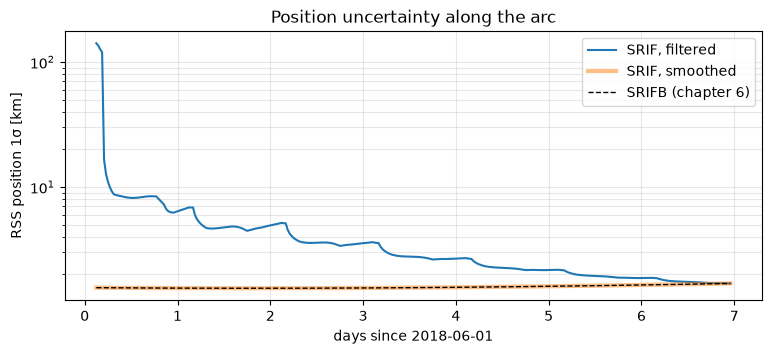

In [4]:
t_est = scb.EpochArray(solution.timestamps, sys="TDB")
t_days = (t_est - epochs[0]).convert_to(day).values


sigma_filtered = [sum(P.diagonal()[:3]) ** 0.5 for P in solution.covariance_est]  # RSS position 1σ
sigma_smoothed = [sum(P.diagonal()[:3]) ** 0.5 for P in solution.covariance_smooth]
sigma_batch = [sum(P[i][i] for i in range(3)) ** 0.5 for P in batch["covariance_full"]]  # final covariances, stored in full

fig, ax = plt.subplots(figsize=(9, 3.5))
ax.semilogy(t_days, sigma_filtered, label="SRIF, filtered")
ax.semilogy(t_days, sigma_smoothed, lw=3, alpha=0.5, label="SRIF, smoothed")
ax.semilogy(t_days, sigma_batch, "k--", lw=1, label="SRIFB (chapter 6)")
ax.set(xlabel="days since 2018-06-01", ylabel="RSS position 1σ [km]", title="Position uncertainty along the arc")
ax.legend()
ax.grid(alpha=0.3, which="both")

print(f"filtered σ after the first epoch: {sigma_filtered[0]:8.2f} km")
print(f"filtered σ at the last epoch:     {sigma_filtered[-1]:8.3f} km   (batch: {sigma_batch[-1]:.3f} km)")
print(f"smoothed σ at the first epoch:    {sigma_smoothed[0]:8.3f} km   (batch: {sigma_batch[0]:.3f} km)")

The filtered uncertainty starts at the level allowed by a single epoch of data and decreases as observations accumulate. At the last epoch the filter has seen all the data, and its estimate and covariance coincide with the batch solution mapped to that epoch. The smoother propagates the final information backward, so the smoothed solution matches the batch solution at every epoch. Without process noise, sequential filtering with smoothing and batch estimation are two algorithms for the same estimate:

In [5]:
estimate_difference = [s - b for s, b in zip(solution.state_est[-1], batch["state_estimated"][-1])]
print(f"SRIF (filtered, last epoch) − SRIFB: |Δr| = {sum(d**2 for d in estimate_difference[:3]) ** 0.5 * 1e6:.1f} mm")

SRIF (filtered, last epoch) − SRIFB: |Δr| = 43.8 mm


## 3. The Kalman filter

`LKF` is the linearized Kalman filter: the same sequential estimator written in covariance form. Swapping it in is a one-line change and gives the same solution, to within the few-centimeter convergence tolerance ([chapter 6](06_first_od_solution.ipynb)); the square-root form is preferred in practice for its numerical robustness.

In [6]:
%%capture fit_log
# 🔵 TODO: remove %%capture once filters and measurement models stop printing progress
lkf = scb.LKF(propagator=reference_propagator(), measurements=tracking,
              settings=scb.FilterSettings(initial_covariance=P0),
              traj_name="reference_lkf.bsp", traj_dir=str(out))
solution_lkf, _, _ = lkf.fit(traj_name="reference_lkf.bsp", traj_dir=str(out), convergence_threshold=1e-5)

In [7]:
difference = [a - b for a, b in zip(solution_lkf.state_est[-1], solution.state_est[-1])]
print(f"LKF − SRIF at the last epoch: |Δr| = {sum(d**2 for d in difference[:3]) ** 0.5 * 1e6:.2f} mm")

LKF − SRIF at the last epoch: |Δr| = 62.25 mm


→ *Model catalogs: Filters* (`LKF`, `SRIF`, `LSB`, `SRIFB`, smoothing, multi-arc)

## 4. An incomplete dynamics model

So far the filter's force model matched the truth exactly. In practice it never does. To see the consequence, the filter below omits solar radiation pressure, an acceleration of about $2\times10^{-11}$ km/s² ([chapter 2](02_truth_dynamics.ipynb)), and processes the same data. The truth is computed once and reused for the rest of the chapter:

In [8]:
%%capture fit_log
# 🔵 TODO: remove %%capture once filters and measurement models stop printing progress
# 🔵 TODO: get_state takes one epoch at a time; replace the loop once it accepts an EpochArray
x_true = [orex.get_state(t, reference_frame="J2000", origin="SUN").quantity.values for t in t_est]

srif_no_srp = scb.SRIF(propagator=reference_propagator(cannonball_SRP=False), measurements=tracking,
                       settings=scb.FilterSettings(initial_covariance=P0),
                       traj_name="reference_no_srp.bsp", traj_dir=str(out))
solution_no_srp, _, _ = srif_no_srp.fit(traj_name="reference_no_srp.bsp", traj_dir=str(out),
                                        convergence_threshold=1e-5)

In [9]:
error_no_srp = [((e[:3] - x[:3]) @ (e[:3] - x[:3])) ** 0.5 for e, x in zip(solution_no_srp.state_est, x_true)]
sigma_no_srp = [sum(P.diagonal()[:3]) ** 0.5 for P in solution_no_srp.covariance_est]
postfit_no_srp = [r / s for dataset in solution_no_srp.postfits.values() for r, s, *_ in dataset]

print(f"position error at the last epoch: {error_no_srp[-1]:6.1f} km")
print(f"reported 1σ at the last epoch:    {sigma_no_srp[-1]:6.1f} km")
print(f"post-fit residual RMS / σ:        {(sum(z**2 for z in postfit_no_srp) / len(postfit_no_srp)) ** 0.5:6.2f}")

position error at the last epoch:   63.7 km
reported 1σ at the last epoch:       1.7 km
post-fit residual RMS / σ:          1.46


The estimate is tens of kilometers off while the filter reports about 1.7 km of uncertainty, an error of dozens of σ. The residuals barely show it: the post-fit RMS rises only from about 1.0 to 1.5 σ, because the filter absorbs the missing acceleration into the weakly observed plane-of-sky components of the state ([chapter 6](06_first_od_solution.ipynb)). An overconfident covariance with nearly normal residuals is the typical signature of unmodeled dynamics.

## 5. Process noise

**Process noise** acknowledges that the dynamics model is imperfect. Between observation epochs the filter adds the covariance $Q_k$ of a random acceleration, so the uncertainty grows and older data are progressively de-weighted. Scarabaeus configures it with `ProcessNoiseSettings`, passed to `FilterSettings`:

| Type | Model | Settings |
|---|---|---|
| `"SNC"` | state noise compensation: white acceleration noise on position and velocity | `Q_cont` (3×3 `CovarianceMatrix`) |
| `"DMC"` | dynamic model compensation: first-order Gauss–Markov accelerations added to the state | `Q_cont`, `beta` (correlation times) |

`Q_cont` can be defined in the inertial frame or, with `frame="RTN"`, in the radial–transverse–normal frame of the spacecraft. DMC and the other stochastic acceleration models are covered in *Model catalogs: Process noise*. Here we use SNC with the same level on each axis:

In [10]:
%%capture fit_log
# 🔵 TODO: remove %%capture once filters and measurement models stop printing progress
sigma_snc = scb.ArrayWUnits(1e-10, km / sec**2)
snc = scb.ProcessNoiseSettings(type="SNC", Q_cont=scb.CovarianceMatrix([sigma_snc] * 3, epochs[0], from_list=True))

srif_snc = scb.SRIF(propagator=reference_propagator(cannonball_SRP=False), measurements=tracking,
                    settings=scb.FilterSettings(initial_covariance=P0, process_noise=snc),
                    traj_name="reference_snc.bsp", traj_dir=str(out))
solution_snc, _, _ = srif_snc.fit(traj_name="reference_snc.bsp", traj_dir=str(out),
                                  convergence_threshold=1e-5)

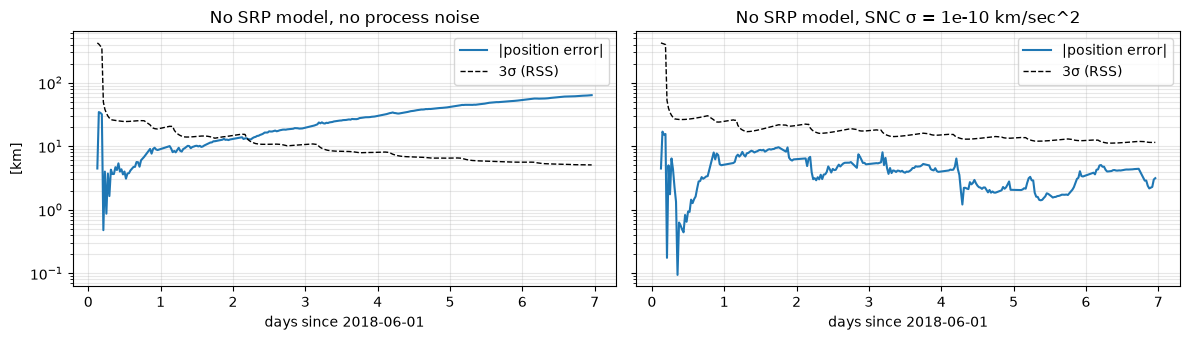

In [11]:
error_snc = [((e[:3] - x[:3]) @ (e[:3] - x[:3])) ** 0.5 for e, x in zip(solution_snc.state_est, x_true)]
sigma_snc_rss = [sum(P.diagonal()[:3]) ** 0.5 for P in solution_snc.covariance_est]

fig, ax = plt.subplots(1, 2, figsize=(12, 3.5), sharey=True)
for a, error, sigma, title in [(ax[0], error_no_srp, sigma_no_srp, "No SRP model, no process noise"),
                               (ax[1], error_snc, sigma_snc_rss, f"No SRP model, SNC σ = {sigma_snc}")]:
    a.semilogy(t_days, error, label="|position error|")
    a.semilogy(t_days, [3 * s for s in sigma], "k--", lw=1, label="3σ (RSS)")
    a.set(xlabel="days since 2018-06-01", title=title)
    a.grid(alpha=0.3, which="both")
    a.legend()
ax[0].set_ylabel("[km]")
plt.tight_layout()

With process noise the covariance no longer collapses: it stays large enough to contain the error that the missing acceleration produces, and the estimate is now consistent with its uncertainty.

### Choosing the noise level

The process noise level is a modeling choice. Too little leaves the filter overconfident; too much discards information and loosens the solution. A scan over σ shows the trade-off:

In [12]:
%%capture fit_log
# 🔵 TODO: remove %%capture once filters and measurement models stop printing progress
scan_results = {}
for value in [1e-12, 1e-11, 1e-10, 1e-9]:
    process_noise = scb.ProcessNoiseSettings(
        type="SNC", Q_cont=scb.CovarianceMatrix([scb.ArrayWUnits(value, km / sec**2)] * 3, epochs[0], from_list=True))
    scan = scb.SRIF(propagator=reference_propagator(cannonball_SRP=False), measurements=tracking,
                    settings=scb.FilterSettings(initial_covariance=P0, process_noise=process_noise),
                    traj_name="reference_scan.bsp", traj_dir=str(out))
    solution_scan, n_scan, _ = scan.fit(traj_name="reference_scan.bsp", traj_dir=str(out), convergence_threshold=1e-5)
    # 🔵 TODO: read state_est before the next fit; read afterwards it returns the last fit's values (scb_suggestions.md 6.79)
    error = [((e[:3] - x[:3]) @ (e[:3] - x[:3])) ** 0.5 for e, x in zip(solution_scan.state_est, x_true)]
    sigma = [sum(P.diagonal()[:3]) ** 0.5 for P in solution_scan.covariance_est]
    postfit = [r / s for dataset in solution_scan.postfits.values() for r, s, *_ in dataset]
    scan_results[value] = error, sigma, (sum(z**2 for z in postfit) / len(postfit)) ** 0.5, n_scan

 σ_SNC [km/s²]  |err| end [km]  1σ end [km]  max |err|/σ  post-fit RMS/σ  iterations
         1e-12           53.85         2.12        25.35            1.36           2
         1e-11           30.32         2.97        11.53            1.10           2
         1e-10            3.14         3.83         1.48            0.73           2
         1e-09            2.75         5.17         1.25            0.71           2


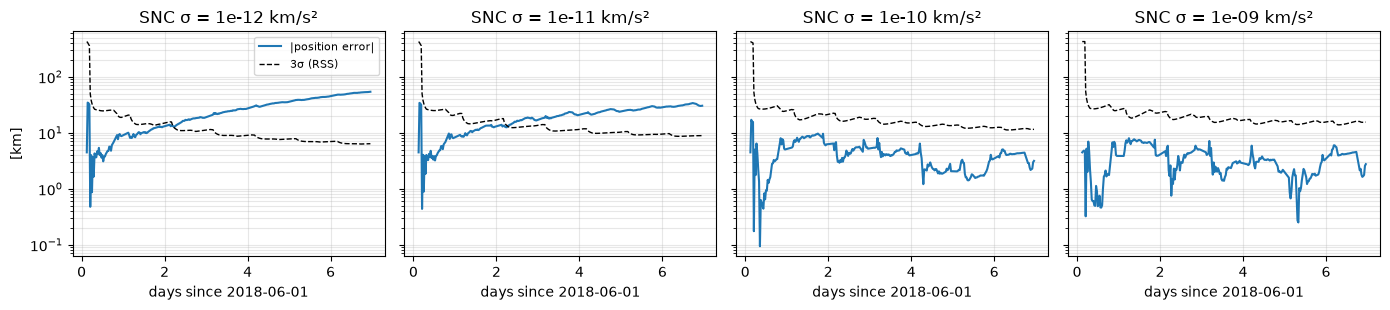

In [13]:
print(f"{'σ_SNC [km/s²]':>14s} {'|err| end [km]':>15s} {'1σ end [km]':>12s} {'max |err|/σ':>12s} {'post-fit RMS/σ':>15s} {'iterations':>11s}")
fig, ax = plt.subplots(1, 4, figsize=(14, 3.2), sharey=True)
for a, (value, (error, sigma, postfit_rms, n_scan)) in zip(ax, scan_results.items()):
    print(f"{value:14.0e} {error[-1]:15.2f} {sigma[-1]:12.2f} {max(e / s for e, s in zip(error, sigma)):12.2f}"
          f" {postfit_rms:15.2f} {n_scan:11d}")
    a.semilogy(t_days, error, label="|position error|")
    a.semilogy(t_days, [3 * s for s in sigma], "k--", lw=1, label="3σ (RSS)")
    a.set(xlabel="days since 2018-06-01", title=f"SNC σ = {value:.0e} km/s²")
    a.grid(alpha=0.3, which="both")
ax[0].set_ylabel("[km]")
ax[0].legend(fontsize=8)
plt.tight_layout()

At the low end the error is still many σ, and the error curve leaves the 3σ band for most of the arc. From about $10^{-10}$ km/s², a few times the SRP acceleration the filter is missing ($2\times10^{-11}$ km/s², [chapter 2](02_truth_dynamics.ipynb)), the error stays within its 3σ over the whole arc; above that the uncertainty keeps growing for little gain. In operations the level is chosen with the same kind of consistency checks: normalized errors in simulations, and residual statistics and solution overlaps with real data.

## 6. Covariance analysis

The covariance of a linear filter depends on the measurement epochs, geometry and weights, not on the measurement values. Covariance analysis uses that to predict the uncertainty a tracking plan would produce before any data exist: it is the standard tool for comparing tracking schedules. With `FilterSettings(covariance_analysis=True)`, each `MeasurementSpec` is given `epochs=` instead of `observed_meas=`, and `fit()` makes a single pass that skips the state update.

Here the epochs come from the [chapter 3](03_tracking_data.ipynb) schedule; in a planning study they would come from a visibility analysis ([chapter 1](01_scenario.ipynb)). The filter is the `SRIF` from section 1 with the correct dynamics, so the predicted uncertainty is the filtered one, epoch by epoch. Three plans:

In [14]:
%%capture fit_log
# 🔵 TODO: remove %%capture once filters and measurement models stop printing progress
plans = {
    "all three complexes, range + range-rate": lambda model: True,
    "without Canberra (DSS-43)": lambda model: "DSS-43" not in model.name,
    "range only": lambda model: isinstance(model, scb.RangeIdeal),
}
predictions = {}
for label, use in plans.items():
    plan = scb.MeasurementSpec.many(*[
        scb.MeasurementSpec(model=model, epochs=observed[model.name][0], dataset_name=model.name)
        for model in models if use(model)
    ])
    analysis = scb.SRIF(propagator=reference_propagator(), measurements=plan,
                        settings=scb.FilterSettings(initial_covariance=P0, covariance_analysis=True),
                        traj_name="covariance_analysis.bsp", traj_dir=str(out))
    prediction = analysis.fit(traj_name="covariance_analysis.bsp", traj_dir=str(out))[0]
    t_prediction = (scb.EpochArray(prediction.timestamps, sys="TDB") - epochs[0]).convert_to(day).values
    predictions[label] = t_prediction, [sum(P.diagonal()[:3]) ** 0.5 for P in prediction.covariance_est]

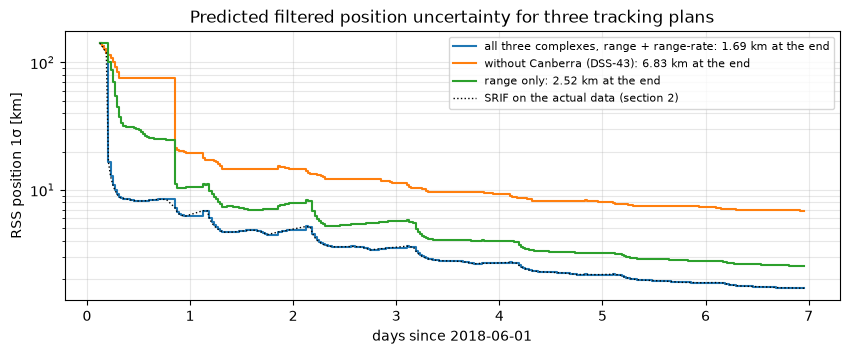

In [15]:
fig, ax = plt.subplots(figsize=(10, 3.5))
for label, (t_prediction, sigma) in predictions.items():
    ax.semilogy(t_prediction, sigma, drawstyle="steps-post", label=f"{label}: {sigma[-1]:.2f} km at the end")
ax.semilogy(t_days, sigma_filtered, "k:", lw=1, label="SRIF on the actual data (section 2)")
ax.set(xlabel="days since 2018-06-01", ylabel="RSS position 1σ [km]",
       title="Predicted filtered position uncertainty for three tracking plans")
ax.legend(fontsize=8)
ax.grid(alpha=0.3, which="both")

The first plan lies on top of the filtered uncertainty of section 2, as it should: with matching models the formal covariance does not depend on the measurement values, so the analysis predicts what the filter will report. Each step down is a pass. Without Canberra, which provides most of the tracking at this declination, the first pass comes almost a day later and the final uncertainty is about four times larger. Without range-rate, it is about 50% larger.

The prediction is only as good as the models behind it: a covariance analysis with the incomplete dynamics of section 4 would promise the same 1.7 km, while the actual error was tens of kilometers. Planning studies therefore include process noise or consider parameters ([chapter 8](08_estimating_more.ipynb)) for the errors they expect.

Process noise accounts for a mismodeled acceleration statistically. When the missing physics is known, an alternative is to estimate its magnitude, for example an SRP scale factor. [Chapter 8](08_estimating_more.ipynb) takes that approach.

## Summary

| Concept | Scarabaeus API |
|---|---|
| Sequential filters | `SRIF(propagator, measurements, settings)`, `LKF(...)`, same interface as the batch filters |
| Smoothing | `fit(if_sequential_smooth=True)` → `deviation_smooth`, `covariance_smooth` |
| Filtered vs. smoothed estimates | `state_est` / `covariance_est` (data up to $t_k$), smoothed quantities (all data) |
| Process noise | `ProcessNoiseSettings(type="SNC", Q_cont=CovarianceMatrix(...))`, `FilterSettings(process_noise=...)` |
| Process noise types | `"SNC"`, `"DMC"` (with `beta`); `Q_cont` in the inertial or RTN frame |
| Covariance analysis | `FilterSettings(covariance_analysis=True)`, `MeasurementSpec(model, epochs=..., dataset_name=...)` |

**Next:** [8. Estimating parameters](08_estimating_more.ipynb) estimates the SRP scale factor and introduces consider parameters.